# Generalised Railway Platform Allocation — Scaling Benchmark V9

## Purpose

V9 is a **scale extension of V8**, not a redesign. It keeps the same frozen **one-hot QUBO formulation**, synthetic generator, feasibility rules, Greedy/SA/SQA methods, exact-search reference, metrics, resource gate, output schema and plots. The only experiment-design changes are the larger FULL-mode train counts and a higher variable cap so the added sizes are not rejected by the old V8 cap. It compares:

- **Greedy:** a classical time-ordered first-fit interval-colouring baseline, reserving short-only platforms for short trains and using randomized tie-breaking;
- **SA:** OpenJij Simulated Annealing;
- **SQA:** OpenJij Simulated Quantum Annealing, which is a **classical simulation**, not quantum hardware.

Exact branch-and-bound is run only on small instances as a reference. A timeout is reported as `TIMEOUT`, never as infeasibility or a proven optimum.

## Generalised problem definition

Every dataset is generated synthetically. There is no station-specific timetable or station-specific data. Each train has a synthetic nominal platform, eligible platform set, coach count, scheduled arrival/departure, delay and actual occupation interval. The allocation rules are:

1. Assign each train to exactly one eligible platform.
2. Two trains with overlapping occupation intervals (including the declared clearance) cannot use the same platform.
3. Trains at or above the synthetic coach threshold can use only the designated long-train-capable platforms.
4. Minimise the number of trains moved from their nominal platform.

The five-minute clearance, six total platforms, four long-train-capable platforms and 24-coach threshold are **modelling assumptions**, not claims about a real railway operator. To prevent large-N instances from becoming physically overloaded simply because the original fixed time horizon was reused, the generator constructs a hidden feasible witness assignment and sequences intervals on each witness platform. The time span therefore grows with the number of trains while target platform utilisation (including clearance occupancy) controls overlap pressure. The witness is never given to Greedy, QUBO, SA or SQA; it is only a feasibility certificate and an exact-search incumbent fallback. In this generator, short-train witness lanes are selected from the short-only platforms and long-train witness lanes from the long-capable pool. The Greedy baseline uses a transparent time-ordered first-fit rule that reserves short-only lanes for short trains; it does not read witness assignments. Low/medium/high also vary nominal-platform mismatch probability. Observed conflict density, mean degree and maximum concurrency are measured rather than assumed.

## Why one-hot is frozen

V7/V7.1 found encoding-dependent behaviour. Domain-wall was promising for SA in the small pilot but showed platform-label sensitivity and weaker SQA raw feasibility in the permutation probe. One-hot is retained as the neutral, interpretable reference representation for the scaling study. V9 does not claim it is universally optimal.

## Study plan

| Mode | Train counts | Independent seeds per size | Purpose |
|---|---|---|---|
| Pilot | 8, 16, 32, 64 | 2 | Check correctness, runtime and resource use |
| Full | 8, 16, 32, 64, 128, 256, 512, 1,024, 1,536, 2,048 | 3 seeds through 256; 2 seeds at 512, 1,024, 1,536 and 2,048 | Main scaling benchmark + extended stress range |

Each size is evaluated under low, medium and high synthetic congestion. The sampler budget is tiered by size to keep the largest tests tractable. SA and SQA receive the same reads/sweeps/repeats for a given dataset. The exact budget used is written to every run row and metadata file. Comparisons across different train counts must account for these tiered budgets. The witness makes instances feasible by construction, but its cost is not an optimum and is not provided to the optimization samplers.

A pre-build resource gate estimates one-hot variables and quadratic interactions. Instances exceeding the configured limits are marked `SKIPPED_RESOURCE_LIMIT` before QUBO construction/sampling. The limits are configurable; a skip is not a solver failure.

## Critical interpretation rules

- Only conflict-free, internally valid raw sampler samples count as feasible. No repair or post-processing is applied.
- `best_valid_cost` is the best valid sample in one solver run; it is not a proof of optimality.
- Exact gaps are populated only for `OPTIMAL` exact-search results.
- If Greedy fails to find a feasible assignment, that is not proof that the instance is infeasible.
- `TIMEOUT`, `INFEASIBLE`, `NOT_RUN_SIZE_LIMIT`, `SKIPPED_RESOURCE_LIMIT` and runtime `ERROR` are distinct statuses.
- Report construction time, sampler time and end-to-end time separately.
- Report the observed number of conflict edges and conflict density; do not assume that the difficulty labels automatically produce ordered hardness.

## How to run

1. Run the notebook from top to bottom with `STUDY_MODE = "PILOT"`.
2. Review identity checks, feasibility, actual conflict density, QUBO sizes and timings.
3. Only after the pilot is satisfactory, change `STUDY_MODE` to `"FULL"`.
4. Preserve the executed notebook and the complete `railway_v9_outputs` folder.

**Do not interpret pilot output as final study evidence.** The full mode is a planned experiment, not a promise that every 2,048-train instance will fit the selected resource limits or finish within a fixed runtime on every machine. The two largest sizes are stress tests; the unchanged large-tier sampler budget is intentionally lightweight and should be interpreted accordingly.

## 0. Environment setup
Run this cell only if required packages are missing. OpenJij 0.12.x was used in the preceding experiments.

In [1]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and machine information

In [2]:
import sys, platform, time, math, json, itertools, random, importlib.metadata, warnings, os, gc
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Install it in this notebook kernel, then restart the kernel.") from exc

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    psutil = None
    RAM_GB = None
try:
    OPENJIJ_VERSION = importlib.metadata.version("openjij")
except Exception:
    OPENJIJ_VERSION = getattr(oj, "__version__", "version not exposed")

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM (GB):", RAM_GB)
print("OpenJij:", OPENJIJ_VERSION)

Python: 3.12.12
OS: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM (GB): 127.65
OpenJij: 0.12.2


## 2. Pre-registered experiment controls

In [3]:
# Change only after reviewing the pilot outputs.
STUDY_MODE = "FULL"  # "PILOT" or "FULL"
RUN_EXPERIMENT = True
RUN_SAMPLERS = True

N_PLATFORMS = 6
LONG_PLATFORM_COUNT = 4
LONG_TRAIN_COACH_THRESHOLD = 24
CLEARANCE_MIN = 5  # Declared modelling assumption, in minutes.
DIFFICULTIES = ["low", "medium", "high"]
GREEDY_RESTARTS = 20
SEED_BASE = 880000

# Exact search is a reference only; larger cases are deliberately not submitted.
EXACT_MAX_TRAINS = 32
EXACT_TIME_LIMIT_S = 2.0

# Pre-build gates. These are experimental safety limits, not mathematical limits.
# V9 raises only the variable cap to admit the planned 1,536/2,048-train sizes.
MAX_QUBO_VARIABLES = 16000
MAX_QUBO_INTERACTIONS = 500000

DIFFICULTY_CONFIG = {
    # Target utilisation is per witness platform and includes occupation plus clearance.
    # Nominal/witness probability controls how often the nominal platform agrees
    # with the generator's feasible schedule; neither field is given to the solvers.
    "low":    {"dwell_min": 12, "dwell_max": 20, "delay_max_min": 3,
                "target_utilization": 0.55, "nominal_witness_probability": 0.80},
    "medium": {"dwell_min": 15, "dwell_max": 25, "delay_max_min": 8,
                "target_utilization": 0.70, "nominal_witness_probability": 0.55},
    "high":   {"dwell_min": 18, "dwell_max": 30, "delay_max_min": 15,
                "target_utilization": 0.84, "nominal_witness_probability": 0.30},
}

# Budget tiers are explicit and exported with every sampler run.
if STUDY_MODE.upper() == "PILOT":
    TRAIN_COUNTS = [8, 16, 32, 64]
    SEEDS_BY_SIZE = {n: [11, 22] for n in TRAIN_COUNTS}
    BUDGET_BY_SIZE = {
        "small": {"repeats": 2, "num_reads": 30, "num_sweeps": 300},
        "medium": {"repeats": 2, "num_reads": 30, "num_sweeps": 300},
        "large": {"repeats": 1, "num_reads": 10, "num_sweeps": 100},
    }
elif STUDY_MODE.upper() == "FULL":
    TRAIN_COUNTS = [8, 16, 32, 64, 128, 256, 512, 1024, 1536, 2048]
    SEEDS_BY_SIZE = {
        8: [11, 22, 33], 16: [11, 22, 33], 32: [11, 22, 33], 64: [11, 22, 33],
        128: [11, 22, 33], 256: [11, 22, 33], 512: [11, 22], 1024: [11, 22],
        1536: [11, 22], 2048: [11, 22],
    }
    BUDGET_BY_SIZE = {
        "small": {"repeats": 3, "num_reads": 40, "num_sweeps": 400},
        "medium": {"repeats": 2, "num_reads": 20, "num_sweeps": 200},
        "large": {"repeats": 1, "num_reads": 8, "num_sweeps": 100},
    }
else:
    raise ValueError("STUDY_MODE must be PILOT or FULL")


def budget_tier(n):
    if n <= 64: return "small"
    if n <= 256: return "medium"
    return "large"

EXPECTED_DATASETS = sum(len(SEEDS_BY_SIZE[n]) for n in TRAIN_COUNTS) * len(DIFFICULTIES)
EXPECTED_CALLS = sum(
    len(SEEDS_BY_SIZE[n]) * len(DIFFICULTIES) * 2 * BUDGET_BY_SIZE[budget_tier(n)]["repeats"]
    for n in TRAIN_COUNTS
)
print("Study mode:", STUDY_MODE)
print("Train counts:", TRAIN_COUNTS)
print("Expected datasets:", EXPECTED_DATASETS)
print("Maximum planned SA/SQA calls before resource skips:", EXPECTED_CALLS)
print("Exact-search limit:", EXACT_MAX_TRAINS, "trains /", EXACT_TIME_LIMIT_S, "seconds per dataset")
print("QUBO gate:", MAX_QUBO_VARIABLES, "variables and", MAX_QUBO_INTERACTIONS, "interactions")
print("Budget tiers:", BUDGET_BY_SIZE)
print("Scenario profiles:", DIFFICULTY_CONFIG)
print("Generator uses a hidden feasible schedule witness; solvers receive no witness variable or warm start.")

Study mode: FULL
Train counts: [8, 16, 32, 64, 128, 256, 512, 1024, 1536, 2048]
Expected datasets: 78
Maximum planned SA/SQA calls before resource skips: 336
Exact-search limit: 32 trains / 2.0 seconds per dataset
QUBO gate: 16000 variables and 500000 interactions
Budget tiers: {'small': {'repeats': 3, 'num_reads': 40, 'num_sweeps': 400}, 'medium': {'repeats': 2, 'num_reads': 20, 'num_sweeps': 200}, 'large': {'repeats': 1, 'num_reads': 8, 'num_sweeps': 100}}
Scenario profiles: {'low': {'dwell_min': 12, 'dwell_max': 20, 'delay_max_min': 3, 'target_utilization': 0.55, 'nominal_witness_probability': 0.8}, 'medium': {'dwell_min': 15, 'dwell_max': 25, 'delay_max_min': 8, 'target_utilization': 0.7, 'nominal_witness_probability': 0.55}, 'high': {'dwell_min': 18, 'dwell_max': 30, 'delay_max_min': 15, 'target_utilization': 0.84, 'nominal_witness_probability': 0.3}}
Generator uses a hidden feasible schedule witness; solvers receive no witness variable or warm start.


## 3. Synthetic railway instance generator and validation

In [4]:
def generate_instance(n_trains: int, difficulty: str, seed: int,
                      n_platforms: int = N_PLATFORMS,
                      long_platform_count: int = LONG_PLATFORM_COUNT,
                      clearance_min: int = CLEARANCE_MIN) -> pd.DataFrame:
    """Generate an always-feasible interval-allocation instance.

    The hidden witness uses the long-capable platform pool for long trains and the
    short-only platform pool for short trains. Intervals are sequenced independently
    on each witness platform. The full eligibility rules remain unchanged for solvers.
    The witness is exported for audit, but never passed to QUBO or samplers.
    """
    if difficulty not in DIFFICULTY_CONFIG:
        raise ValueError(f"Unknown difficulty: {difficulty}")
    if n_trains < 1 or n_platforms < 2:
        raise ValueError("Need at least one train and two platforms")
    if not 1 <= long_platform_count <= n_platforms:
        raise ValueError("Invalid long-platform count")
    cfg = DIFFICULTY_CONFIG[difficulty]
    rng = np.random.default_rng(seed)
    drafts = []
    witness_loads = {p:0 for p in range(n_platforms)}

    # Determine train attributes and a hidden feasible witness platform.
    for i in range(n_trains):
        coaches = int(rng.integers(10,31))
        is_long = coaches >= LONG_TRAIN_COACH_THRESHOLD
        eligible = list(range(long_platform_count)) if is_long else list(range(n_platforms))
        # The generator witness uses disjoint lane pools: long-capable platforms
        # for long trains, and the remaining short-only platforms for short trains.
        # Solver eligibility is unchanged: short trains may still use every platform.
        witness_pool = list(range(long_platform_count)) if is_long else list(range(long_platform_count,n_platforms))
        if not witness_pool:
            raise ValueError("At least one short-only platform is required for this witness generator")
        min_load = min(witness_loads[p] for p in witness_pool)
        balanced_candidates = [p for p in witness_pool if witness_loads[p] == min_load]
        witness_platform = int(rng.choice(balanced_candidates))
        witness_loads[witness_platform] += 1
        dwell = int(rng.integers(cfg["dwell_min"],cfg["dwell_max"]+1))
        delay = int(rng.integers(0,cfg["delay_max_min"]+1))
        drafts.append({
            "train_index":i,"train_id":f"T{i+1:05d}","coaches":coaches,
            "is_long":bool(is_long),"eligible_platforms":eligible,
            "witness_platform":witness_platform,"dwell_min":dwell,"delay_min":delay,
        })

    # Create a separate chronological lane on each witness platform.
    # Mean idle gap is selected from target utilisation; this keeps load intensity
    # approximately comparable as N grows instead of overloading a fixed time horizon.
    platform_orders = {p:[] for p in range(n_platforms)}
    for item in drafts:
        platform_orders[item["witness_platform"]].append(item["train_index"])
    for p in range(n_platforms):
        rng.shuffle(platform_orders[p])

    times = {}
    mean_dwell = (cfg["dwell_min"] + cfg["dwell_max"]) / 2.0
    target_u = float(cfg["target_utilization"])
    mean_occupied = mean_dwell + int(clearance_min)
    mean_gap = mean_occupied * (1.0-target_u) / target_u
    for p, order in platform_orders.items():
        cursor = 60  # warm-up offset ensures scheduled arrival remains nonnegative after delay
        for i in order:
            gap = max(0,int(round(rng.exponential(mean_gap)))) if mean_gap > 0 else 0
            actual_arrival = cursor + gap
            item = drafts[i]
            actual_departure = actual_arrival + item["dwell_min"]
            scheduled_arrival = actual_arrival - item["delay_min"]
            times[i] = {
                "scheduled_arrival_min":scheduled_arrival,
                "scheduled_departure_min":scheduled_arrival + item["dwell_min"],
                "actual_arrival_min":actual_arrival,
                "actual_departure_min":actual_departure,
            }
            cursor = actual_departure + int(clearance_min)

    rows=[]
    for item in drafts:
        eligible=item["eligible_platforms"]
        witness=item["witness_platform"]
        if rng.random() < float(cfg["nominal_witness_probability"]):
            nominal=witness
        else:
            alternatives=[p for p in eligible if p != witness]
            nominal=int(rng.choice(alternatives)) if alternatives else witness
        rows.append({
            **item,**times[item["train_index"]],
            "nominal_platform":int(nominal),
            "difficulty":difficulty,"seed":int(seed),
            "target_utilization":target_u,
            "nominal_witness_probability":float(cfg["nominal_witness_probability"]),
        })
    return pd.DataFrame(rows)


def interval_conflicts(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN) -> List[Tuple[int,int]]:
    edges=[]
    n=len(df)
    starts=df["actual_arrival_min"].astype(int).to_numpy()
    ends=(df["actual_departure_min"].astype(int)+int(clearance_min)).to_numpy()
    for i in range(n):
        overlap=(starts[i] < ends[i+1:]) & (starts[i+1:] < ends[i])
        edges.extend((i,i+1+int(offset)) for offset in np.flatnonzero(overlap))
    return edges


def max_interval_concurrency(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN,
                             long_only: bool = False) -> int:
    subset=df[df.is_long] if long_only else df
    events=[]
    for row in subset.itertuples():
        events.append((int(row.actual_arrival_min),1))
        events.append((int(row.actual_departure_min)+int(clearance_min),-1))
    # End events before start events at equal time: intervals are half-open.
    events.sort(key=lambda x:(x[0],x[1]))
    active=peak=0
    for _,delta in events:
        active+=delta
        peak=max(peak,active)
    return int(peak)


def assignment_cost(assignment: Dict[int,int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def validate_assignment(assignment: Optional[Dict[int,int]], df: pd.DataFrame,
                        conflicts: List[Tuple[int,int]]) -> Tuple[bool,List[str]]:
    if assignment is None or set(assignment) != set(range(len(df))):
        return False,["missing_train_assignment"]
    violations=[]
    for i,p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i,j in conflicts:
        if assignment.get(i)==assignment.get(j):
            violations.append(f"overlap_conflict_{i}_{j}")
    return len(violations)==0,violations


def conflict_density(n_trains: int, conflicts: List[Tuple[int,int]]) -> float:
    possible=n_trains*(n_trains-1)/2
    return len(conflicts)/possible if possible else 0.0

print("Capacity-aware synthetic generator and validators defined.")

Capacity-aware synthetic generator and validators defined.


## 4. Greedy baseline and bounded exact reference

In [5]:
def greedy_assignment(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                      seed: int = 0, restarts: int = GREEDY_RESTARTS) -> Optional[Dict[int,int]]:
    """Time-ordered interval greedy with a least-flexible-platform reservation rule.

    Long trains use the long-capable pool. Short trains prefer the short-only pool;
    that pool is sufficient because the generator's hidden witness schedules short
    trains on those lanes. The method does not read or use witness_platform.
    Random tie-breaking yields multiple feasible assignments; best cost is retained.
    """
    n=len(df)
    master_rng=np.random.default_rng(seed)
    best=None; best_cost=float("inf")
    short_only_platforms=list(range(LONG_PLATFORM_COUNT,N_PLATFORMS))
    for _ in range(max(1,int(restarts))):
        rng=np.random.default_rng(int(master_rng.integers(0,2**31-1)))
        order=sorted(
            range(n),
            key=lambda i:(int(df.iloc[i].actual_arrival_min),
                          not bool(df.iloc[i].is_long),
                          float(rng.random()),i)
        )
        available_at={p:-10**18 for p in range(N_PLATFORMS)}
        platform_load={p:0 for p in range(N_PLATFORMS)}
        assigned={}
        for i in order:
            eligible=[int(p) for p in df.iloc[i].eligible_platforms]
            start=int(df.iloc[i].actual_arrival_min)
            available=[p for p in eligible if available_at[p] <= start]
            if not bool(df.iloc[i].is_long):
                # Reserve long-capable platforms for long trains whenever a short-only
                # platform can serve the current short train.
                short_available=[p for p in available if p in short_only_platforms]
                if short_available:
                    available=short_available
            if not available:
                break
            nominal=int(df.iloc[i].nominal_platform)
            available.sort(key=lambda p:(p!=nominal,platform_load[p],float(rng.random())))
            p=available[0]
            assigned[i]=p
            available_at[p]=int(df.iloc[i].actual_departure_min)+CLEARANCE_MIN
            platform_load[p]+=1
        if len(assigned)==n:
            valid,_=validate_assignment(assigned,df,conflicts)
            if valid:
                cost=assignment_cost(assigned,df)
                if cost<best_cost:
                    best,best_cost=assigned.copy(),cost
                if best_cost==0:
                    break
    return best

print("Interval-first-fit Greedy baseline defined.")


def exact_branch_and_bound(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                           incumbent: Optional[Dict[int,int]] = None,
                           time_limit_s: float = EXACT_TIME_LIMIT_S) -> Dict[str,Any]:
    """Bounded exact search; timeout is never labelled optimal or infeasible."""
    n=len(df)
    neighbours=[set() for _ in range(n)]
    for i,j in conflicts:
        neighbours[i].add(j); neighbours[j].add(i)
    best_assignment=None; best_cost=float("inf")
    if incumbent is not None:
        ok,_=validate_assignment(incumbent,df,conflicts)
        if ok:
            best_assignment=dict(incumbent)
            best_cost=assignment_cost(best_assignment,df)
    start=time.perf_counter(); nodes=0; timed_out=False

    def recurse(assigned: Dict[int,int], current_cost: int):
        nonlocal best_assignment,best_cost,nodes,timed_out
        nodes+=1
        if time.perf_counter()-start >= time_limit_s:
            timed_out=True
            return
        if len(assigned)==n:
            if current_cost<best_cost:
                best_cost=current_cost; best_assignment=dict(assigned)
            return
        domains={}
        for i in range(n):
            if i in assigned: continue
            used={assigned[j] for j in neighbours[i] if j in assigned}
            domains[i]=[int(p) for p in df.iloc[i].eligible_platforms if int(p) not in used]
            if not domains[i]: return
        lower_bound=current_cost
        for i,options in domains.items():
            if int(df.iloc[i].nominal_platform) not in options:
                lower_bound+=1
        if lower_bound>=best_cost: return
        i=min(domains,key=lambda k:(len(domains[k]),-len(neighbours[k]),k))
        nominal=int(df.iloc[i].nominal_platform)
        for p in sorted(domains[i],key=lambda p:(p!=nominal,p)):
            new_cost=current_cost+int(p!=nominal)
            if new_cost>=best_cost: continue
            assigned[i]=p
            recurse(assigned,new_cost)
            del assigned[i]
            if timed_out: return

    recurse({},0)
    elapsed=time.perf_counter()-start
    if timed_out: status="TIMEOUT"
    elif best_assignment is None: status="INFEASIBLE"
    else: status="OPTIMAL"
    return {"status":status,"assignment":best_assignment,
            "cost":best_cost if best_assignment is not None else None,
            "runtime_s":elapsed,"nodes":nodes}

print("Exact branch-and-bound reference solver defined.")

Interval-first-fit Greedy baseline defined.
Exact branch-and-bound reference solver defined.


## 5. Scalable one-hot QUBO construction

The V9 builder uses the one-hot objective directly rather than repeated symbolic-polynomial copying. For each train `i` and eligible platform `p`, binary variable `x[i,p]` is 1 when that platform is selected.

\[
E(x)=\sum_{i,p\ne p_i^0}x_{ip}
+\lambda\sum_i\left(\sum_{p\in P_i}x_{ip}-1\right)^2
+\lambda\sum_{(i,j)\in C}\sum_{p\in P_i\cap P_j}x_{ip}x_{jp}
\]

where `C` is the temporal conflict edge set and `λ = N + 1`. The feasible objective is at most `N`, so a violated unit constraint carries a penalty larger than the full feasible objective range. The model size is estimated before allocation: variables are eligible train-platform pairs; interactions are within-train one-hot pairs plus shared-platform conflict pairs.

In [6]:
def add_qubo_term(Q, a, b, value):
    key = (a, b) if a <= b else (b, a)
    Q[key] = Q.get(key, 0.0) + float(value)
    if abs(Q[key]) < 1e-12:
        del Q[key]


def estimate_one_hot_size(df, conflicts):
    variables = sum(len(row.eligible_platforms) for row in df.itertuples())
    assignment_interactions = sum(
        len(row.eligible_platforms) * (len(row.eligible_platforms) - 1) // 2
        for row in df.itertuples()
    )
    conflict_interactions = 0
    for i, j in conflicts:
        common = set(map(int, df.iloc[i].eligible_platforms)).intersection(map(int, df.iloc[j].eligible_platforms))
        conflict_interactions += len(common)
    return {
        "estimated_variables": int(variables),
        "estimated_assignment_interactions": int(assignment_interactions),
        "estimated_conflict_interactions": int(conflict_interactions),
        "estimated_quadratic_interactions": int(assignment_interactions + conflict_interactions),
    }


def build_one_hot(df, conflicts, n_platforms=N_PLATFORMS):
    n = len(df)
    lam = float(n + 1)
    Q = {}
    offset = 0.0
    y = {}
    variables = []
    for i in range(n):
        eligible = [int(p) for p in df.iloc[i].eligible_platforms]
        names = []
        for p in eligible:
            name = f"oh_{i}_{p}"
            y[(i,p)] = name; variables.append(name); names.append(name)
            # Reassignment objective.
            if p != int(df.iloc[i].nominal_platform):
                add_qubo_term(Q, name, name, 1.0)
        # lambda * (sum(x)-1)^2 = lambda - lambda*sum(x) + 2lambda*sum(x_i*x_j)
        offset += lam
        for name in names:
            add_qubo_term(Q, name, name, -lam)
        for a, b in itertools.combinations(names, 2):
            add_qubo_term(Q, a, b, 2.0 * lam)
    for i, j in conflicts:
        common = set(map(int, df.iloc[i].eligible_platforms)).intersection(map(int, df.iloc[j].eligible_platforms))
        for p in common:
            add_qubo_term(Q, y[(i,p)], y[(j,p)], lam)
    return {"encoding":"one_hot", "Q":Q, "offset":float(offset),
            "variables":variables, "y":y, "lambda_assign":lam,
            "lambda_conflict":lam, "penalties":{"assignment":lam,"conflict":lam}}


def qubo_metrics(Q, variables, offset):
    nvar = len(variables)
    interactions = sum(1 for a,b in Q if a != b)
    coeffs = [abs(v) for v in Q.values() if abs(v) > 1e-12]
    possible = nvar * (nvar - 1) / 2
    return {
        "n_variables":nvar,
        "n_linear_terms":sum(1 for a,b in Q if a == b),
        "n_quadratic_interactions":interactions,
        "interaction_density":interactions / possible if possible else 0.0,
        "max_abs_coefficient":max(coeffs) if coeffs else 0.0,
        "min_abs_nonzero_coefficient":min(coeffs) if coeffs else 0.0,
        "offset":float(offset),
    }


def evaluate_qubo(Q, offset, sample):
    total = float(offset)
    for (a,b), coefficient in Q.items():
        total += float(coefficient) * int(sample.get(a,0)) * int(sample.get(b,0))
    return float(total)


def direct_one_hot_energy(sample, df, conflicts, lam):
    total = 0.0
    for i in range(len(df)):
        selected = [int(sample.get(f"oh_{i}_{p}",0)) for p in df.iloc[i].eligible_platforms]
        total += sum(
            int(int(p) != int(df.iloc[i].nominal_platform)) * int(sample.get(f"oh_{i}_{p}",0))
            for p in df.iloc[i].eligible_platforms
        )
        total += lam * (sum(selected) - 1) ** 2
    for i,j in conflicts:
        common = set(map(int, df.iloc[i].eligible_platforms)).intersection(map(int, df.iloc[j].eligible_platforms))
        total += lam * sum(int(sample.get(f"oh_{i}_{p}",0)) * int(sample.get(f"oh_{j}_{p}",0)) for p in common)
    return float(total)

print("Direct one-hot QUBO builder and size estimator defined.")

Direct one-hot QUBO builder and size estimator defined.


## 6. Raw sample decoding and exact QUBO identity tests

In [7]:
def encode_assignment(assignment, df, model):
    sample = {v:0 for v in model["variables"]}
    for i,p in assignment.items():
        sample[model["y"][(int(i),int(p))]] = 1
    return sample


def decode_raw_sample(sample, df, conflicts, model):
    assignment = {}
    for i in range(len(df)):
        eligible = [int(p) for p in df.iloc[i].eligible_platforms]
        selected = [p for p in eligible if int(sample.get(model["y"][(i,p)],0)) == 1]
        if len(selected) != 1:
            return False, None, "one_hot_cardinality"
        assignment[i] = selected[0]
    valid, violations = validate_assignment(assignment,df,conflicts)
    if not valid:
        return False, None, ";".join(violations[:5])
    return True, assignment, ""


def run_one_hot_identity_check(df, conflicts, tests=30, seed=123):
    model = build_one_hot(df,conflicts,N_PLATFORMS)
    rng = np.random.default_rng(seed)
    max_error = 0.0
    for _ in range(tests):
        # Random raw bitstrings test the full polynomial, including invalid one-hot states.
        sample = {v:int(rng.integers(0,2)) for v in model["variables"]}
        q_energy = evaluate_qubo(model["Q"],model["offset"],sample)
        direct = direct_one_hot_energy(sample,df,conflicts,model["lambda_conflict"])
        max_error = max(max_error,abs(q_energy-direct))
    return {"tests":tests,"max_abs_energy_error":max_error,"passed":max_error<1e-8}


def exhaustive_tiny_one_hot_test():
    tiny = pd.DataFrame([
        {"train_index":0,"train_id":"A","nominal_platform":0,"eligible_platforms":[0,1,2]},
        {"train_index":1,"train_id":"B","nominal_platform":0,"eligible_platforms":[0,1,2]},
    ])
    edges = [(0,1)]
    model = build_one_hot(tiny,edges,3)
    variables = model["variables"]
    nstates = 1 << len(variables)
    best_energy = float("inf")
    for bits in range(nstates):
        sample = {name:(bits >> k) & 1 for k,name in enumerate(variables)}
        best_energy = min(best_energy,evaluate_qubo(model["Q"],model["offset"],sample))
    categorical = []
    for a in range(3):
        for b in range(3):
            if a != b:
                assignment = {0:a,1:b}
                categorical.append(assignment_cost(assignment,tiny))
    expected = min(categorical)
    return {"variables":len(variables),"enumerated_bitstrings":nstates,
            "expected_categorical_optimum":expected,"qubo_ground_energy":best_energy,
            "passed":bool(abs(best_energy-expected)<1e-8)}

_preview_df = generate_instance(8,"medium",991)
_preview_edges = interval_conflicts(_preview_df)
_preview_check = run_one_hot_identity_check(_preview_df,_preview_edges,tests=50,seed=1901)
_tiny_check = exhaustive_tiny_one_hot_test()
print("Random raw-bitstring identity check:",_preview_check)
print("Exhaustive tiny one-hot check:",_tiny_check)
if not _preview_check["passed"] or not _tiny_check["passed"]:
    raise AssertionError("One-hot QUBO identity/ground-state validation failed.")

Random raw-bitstring identity check: {'tests': 50, 'max_abs_energy_error': 0.0, 'passed': True}
Exhaustive tiny one-hot check: {'variables': 6, 'enumerated_bitstrings': 64, 'expected_categorical_optimum': 1, 'qubo_ground_energy': 1.0, 'passed': True}


## 7. OpenJij wrapper and runtime metrics

In [8]:
def normalize_qubo(Q, offset):
    max_abs = max([abs(v) for v in Q.values()] or [1.0])
    scale = 1.0 / max_abs if max_abs > 0 else 1.0
    return {k:v*scale for k,v in Q.items()}, float(offset)*scale, scale


def run_openjij(model, df, conflicts, algorithm, num_reads, num_sweeps, seed):
    if algorithm.upper() == "SA":
        sampler = oj.SASampler()
    elif algorithm.upper() == "SQA":
        sampler = oj.SQASampler()
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")
    Q_scaled, offset_scaled, scale = normalize_qubo(model["Q"],model["offset"])
    start = time.perf_counter()
    response = sampler.sample_qubo(Q_scaled,num_reads=int(num_reads),num_sweeps=int(num_sweeps),seed=int(seed))
    runtime = time.perf_counter() - start
    variables = list(response.variables)
    total_reads = valid_reads = 0
    best_cost = None; best_assignment = None; valid_cost_sum = 0.0
    invalid_reasons = {}
    for sample_arr, energy, occurrence in response.record:
        sample = dict(zip(variables,[int(v) for v in sample_arr]))
        occ = int(occurrence)
        total_reads += occ
        valid, assignment, reason = decode_raw_sample(sample,df,conflicts,model)
        if valid:
            cost = assignment_cost(assignment,df)
            valid_reads += occ
            valid_cost_sum += cost * occ
            if best_cost is None or cost < best_cost:
                best_cost, best_assignment = cost, assignment
        else:
            invalid_reasons[reason] = invalid_reasons.get(reason,0) + occ
    return {
        "runtime_s":runtime,"total_reads":total_reads,"valid_reads":valid_reads,
        "raw_feasibility_pct":100*valid_reads/total_reads if total_reads else 0.0,
        "best_valid_cost":best_cost,"mean_valid_cost":valid_cost_sum/valid_reads if valid_reads else np.nan,
        "best_valid_assignment":best_assignment,"invalid_reasons_json":json.dumps(invalid_reasons),
        "normalization_scale":scale,"sampler_info":getattr(response,"info",{}),
    }

print("OpenJij wrapper defined. SQA is a classical simulation.")

OpenJij wrapper defined. SQA is a classical simulation.


## 8. Benchmark execution

In [9]:
def make_dataset_id(n,difficulty,seed):
    return f"N{n}_{difficulty.upper()}_S{seed}"


def run_study():
    dataset_rows=[]; train_rows=[]; edge_rows=[]; model_rows=[]; run_rows=[]
    dataset_cache={}
    for n in TRAIN_COUNTS:
        tier = budget_tier(n)
        budget = BUDGET_BY_SIZE[tier]
        for difficulty in DIFFICULTIES:
            for data_seed in SEEDS_BY_SIZE[n]:
                dataset_id = make_dataset_id(n,difficulty,data_seed)
                derived_seed = int(data_seed + n*1009 + DIFFICULTIES.index(difficulty)*100003)
                df = generate_instance(n,difficulty,derived_seed)
                conflicts = interval_conflicts(df,CLEARANCE_MIN)
                greedy_start = time.perf_counter()
                greedy = greedy_assignment(df,conflicts,seed=derived_seed+5,restarts=GREEDY_RESTARTS)
                greedy_runtime = time.perf_counter()-greedy_start
                witness = {int(row.train_index):int(row.witness_platform) for row in df.itertuples()}
                witness_ok,witness_violations = validate_assignment(witness,df,conflicts)
                if not witness_ok:
                    raise AssertionError(f"Generator witness invalid for {dataset_id}: {witness_violations[:5]}")
                witness_cost = assignment_cost(witness,df)
                greedy_ok = greedy is not None
                greedy_cost = assignment_cost(greedy,df) if greedy_ok else np.nan
                exact_incumbent = greedy if greedy_ok and greedy_cost <= witness_cost else witness
                exact_incumbent_source = "greedy" if exact_incumbent is greedy else "generator_witness"
                exact_start = time.perf_counter()
                if n <= EXACT_MAX_TRAINS:
                    exact = exact_branch_and_bound(df,conflicts,incumbent=exact_incumbent,time_limit_s=EXACT_TIME_LIMIT_S)
                else:
                    exact = {"status":"NOT_RUN_SIZE_LIMIT","assignment":None,"cost":None,"runtime_s":0.0,"nodes":0}
                exact_wall = time.perf_counter()-exact_start

                size_est = estimate_one_hot_size(df,conflicts)
                density = conflict_density(n,conflicts)
                observed_platform_utils=[]
                for _, platform_group in df.groupby("witness_platform"):
                    span=int(platform_group.actual_departure_min.max()+CLEARANCE_MIN-platform_group.actual_arrival_min.min())
                    occupied=float((platform_group.actual_departure_min-platform_group.actual_arrival_min+CLEARANCE_MIN).sum())
                    if span>0:
                        observed_platform_utils.append(occupied/span)
                mean_observed_util=float(np.mean(observed_platform_utils)) if observed_platform_utils else np.nan
                resource_skip = (size_est["estimated_variables"] > MAX_QUBO_VARIABLES or
                                 size_est["estimated_quadratic_interactions"] > MAX_QUBO_INTERACTIONS)
                diag = {
                    "dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                    "derived_seed":derived_seed,"budget_tier":tier,
                    "n_platforms":N_PLATFORMS,"n_conflict_edges":len(conflicts),"conflict_density":density,
                    "nominal_same_platform_conflicts":sum(1 for i,j in conflicts if int(df.iloc[i].nominal_platform)==int(df.iloc[j].nominal_platform)),
                    "mean_conflict_degree":(2*len(conflicts)/n if n else 0.0),
                    "max_concurrent_trains":max_interval_concurrency(df,CLEARANCE_MIN),
                    "max_concurrent_long_trains":max_interval_concurrency(df,CLEARANCE_MIN,long_only=True),
                    "schedule_span_min":int(df.actual_departure_min.max()+CLEARANCE_MIN-df.actual_arrival_min.min()),
                    "target_platform_utilization":float(df.target_utilization.iloc[0]),
                    "mean_observed_witness_platform_utilization":mean_observed_util,
                    "nominal_witness_probability":float(df.nominal_witness_probability.iloc[0]),
                    "eligible_train_platform_pairs":size_est["estimated_variables"],
                    "long_train_count":int(df.is_long.sum()),"witness_feasible":witness_ok,
                    "witness_cost":witness_cost,"exact_incumbent_source":exact_incumbent_source,
                    "greedy_feasible":greedy_ok,"greedy_cost":greedy_cost,"greedy_runtime_s":greedy_runtime,
                    "exact_status":exact["status"],
                    "exact_cost":exact["cost"] if exact["status"]=="OPTIMAL" else np.nan,
                    "exact_incumbent_cost":exact["cost"] if exact["assignment"] is not None else np.nan,
                    "exact_runtime_s":exact["runtime_s"],"exact_wall_s":exact_wall,"exact_nodes":exact["nodes"],
                    "exact_max_trains":EXACT_MAX_TRAINS,"resource_gate_passed":not resource_skip,
                    **size_est,
                }
                dataset_rows.append(diag)
                dataset_cache[dataset_id] = {"df":df,"conflicts":conflicts,"greedy":greedy,
                                             "witness":witness,"exact":exact,"model":None}
                for row in df.to_dict("records"):
                    train_rows.append({"dataset_id":dataset_id,**{k:(json.dumps(v) if isinstance(v,list) else v) for k,v in row.items()}})
                for i,j in conflicts:
                    edge_rows.append({"dataset_id":dataset_id,"train_i":i,"train_j":j})

                # Record predicted model size even when the resource gate rejects construction.
                model_row = {
                    "dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,
                    "build_status":"SKIPPED_RESOURCE_LIMIT" if resource_skip else "PENDING",
                    **size_est,
                }
                model = None
                build_time = np.nan
                if not resource_skip:
                    # Direct builder is O(number of QUBO terms) and avoids repeated polynomial dict copies.
                    check = run_one_hot_identity_check(df,conflicts,tests=12,seed=derived_seed+500)
                    if not check["passed"]:
                        raise AssertionError(f"QUBO identity check failed for {dataset_id}: {check}")
                    build_start = time.perf_counter()
                    model = build_one_hot(df,conflicts,N_PLATFORMS)
                    build_time = time.perf_counter()-build_start
                    metrics = qubo_metrics(model["Q"],model["variables"],model["offset"])
                    if metrics["n_variables"] != size_est["estimated_variables"] or metrics["n_quadratic_interactions"] != size_est["estimated_quadratic_interactions"]:
                        raise AssertionError(f"Estimated and built QUBO sizes differ for {dataset_id}")
                    model_row.update(metrics)
                    model_row.update({"build_status":"BUILT","build_time_s":build_time,
                                      "identity_tests":check["tests"],"identity_max_abs_error":check["max_abs_energy_error"],
                                      "identity_passed":check["passed"],"penalties_json":json.dumps(model["penalties"])})
                else:
                    model_row.update({"n_variables":size_est["estimated_variables"],
                                      "n_quadratic_interactions":size_est["estimated_quadratic_interactions"],
                                      "build_time_s":np.nan,"identity_tests":0,"identity_max_abs_error":np.nan,
                                      "identity_passed":False,"penalties_json":"{}"})
                model_rows.append(model_row)

                if not RUN_SAMPLERS or resource_skip:
                    run_status = "SKIPPED_RESOURCE_LIMIT" if resource_skip else "SAMPLERS_DISABLED"
                    for algorithm in ["SA","SQA"]:
                        for repeat in range(int(budget["repeats"])):
                            run_rows.append({
                                "dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                                "encoding":"one_hot","algorithm":algorithm,"repeat":repeat,
                                "run_status":run_status,"error":"","runtime_s":np.nan,"build_time_s":build_time,
                                "end_to_end_s":np.nan,"num_reads":budget["num_reads"],"num_sweeps":budget["num_sweeps"],
                                "raw_feasibility_pct":np.nan,"total_reads":0,"valid_reads":0,
                                "best_valid_cost":np.nan,"mean_valid_cost":np.nan,
                                "greedy_cost":greedy_cost,"exact_status":exact["status"],
                                "exact_proven_cost":exact["cost"] if exact["status"]=="OPTIMAL" else np.nan,
                                "gap_to_exact":np.nan,"gap_to_greedy":np.nan,
                                "n_variables":size_est["estimated_variables"],
                                "n_quadratic_interactions":size_est["estimated_quadratic_interactions"],
                                "normalization_scale":np.nan,"invalid_reasons_json":"{}"})
                    continue

                for algorithm in ["SA","SQA"]:
                    for repeat in range(int(budget["repeats"])):
                        run_seed = SEED_BASE + derived_seed*17 + (0 if algorithm=="SA" else 50000) + repeat
                        start_run = time.perf_counter()
                        try:
                            result = run_openjij(model,df,conflicts,algorithm,
                                                 budget["num_reads"],budget["num_sweeps"],run_seed)
                            status,error = "OK",""
                        except Exception as exc:
                            result = {"runtime_s":np.nan,"total_reads":0,"valid_reads":0,
                                      "raw_feasibility_pct":np.nan,"best_valid_cost":np.nan,
                                      "mean_valid_cost":np.nan,"normalization_scale":np.nan,
                                      "invalid_reasons_json":"{}"}
                            status,error = "ERROR",f"{type(exc).__name__}: {exc}"
                        end_to_end = time.perf_counter()-start_run
                        exact_proven = exact["cost"] if exact["status"]=="OPTIMAL" else np.nan
                        gap_exact = (result["best_valid_cost"]-exact_proven) if pd.notna(result["best_valid_cost"]) and pd.notna(exact_proven) else np.nan
                        gap_greedy = (result["best_valid_cost"]-greedy_cost) if pd.notna(result["best_valid_cost"]) and pd.notna(greedy_cost) else np.nan
                        if pd.notna(gap_exact) and gap_exact < 0:
                            raise AssertionError("Sampler reported a cost below a proven exact optimum.")
                        run_rows.append({
                            "dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                            "encoding":"one_hot","algorithm":algorithm,"repeat":repeat,
                            "run_status":status,"error":error,"runtime_s":result["runtime_s"],
                            "build_time_s":build_time,"end_to_end_s":end_to_end,
                            "num_reads":budget["num_reads"],"num_sweeps":budget["num_sweeps"],
                            "total_reads":result["total_reads"],"valid_reads":result["valid_reads"],
                            "raw_feasibility_pct":result["raw_feasibility_pct"],
                            "best_valid_cost":result["best_valid_cost"],"mean_valid_cost":result["mean_valid_cost"],
                            "greedy_cost":greedy_cost,"exact_status":exact["status"],"exact_proven_cost":exact_proven,
                            "gap_to_exact":gap_exact,"gap_to_greedy":gap_greedy,
                            "n_variables":size_est["estimated_variables"],
                            "n_quadratic_interactions":size_est["estimated_quadratic_interactions"],
                            "normalization_scale":result["normalization_scale"],
                            "invalid_reasons_json":result["invalid_reasons_json"],
                        })
                # Free large local references between datasets.
                del model
                gc.collect()

    return (pd.DataFrame(dataset_rows),pd.DataFrame(train_rows),pd.DataFrame(edge_rows),
            pd.DataFrame(model_rows),pd.DataFrame(run_rows),dataset_cache)

if RUN_EXPERIMENT:
    (dataset_diagnostics,generated_train_tables,conflict_edge_tables,
     qubo_model_metrics,sampler_runs,dataset_cache) = run_study()
    print("Completed datasets:",len(dataset_diagnostics))
    print("Sampler rows:",len(sampler_runs))
    display(dataset_diagnostics.head())
    display(qubo_model_metrics.groupby("build_status").agg(
        datasets=("dataset_id","nunique"),mean_variables=("n_variables","mean"),
        mean_interactions=("n_quadratic_interactions","mean")).reset_index())
else:
    dataset_diagnostics=generated_train_tables=conflict_edge_tables=qubo_model_metrics=sampler_runs=pd.DataFrame()
    dataset_cache={}
    print("Experiment disabled.")

Completed datasets: 78
Sampler rows: 336


,dataset_id,n_trains,difficulty,seed,derived_seed,budget_tier,n_platforms,n_conflict_edges,conflict_density,nominal_same_platform_conflicts,...,exact_incumbent_cost,exact_runtime_s,exact_wall_s,exact_nodes,exact_max_trains,resource_gate_passed,estimated_variables,estimated_assignment_interactions,estimated_conflict_interactions,estimated_quadratic_interactions
0,N8_LOW_S11,8,low,11,8083,small,6,10,0.357143,0,...,0.0,0.003121,0.003792,9,32,True,42,93,46,139
1,N8_LOW_S22,8,low,22,8094,small,6,6,0.214286,0,...,0.0,0.000896,0.001805,1,32,True,44,102,28,130
2,N8_LOW_S33,8,low,33,8105,small,6,8,0.285714,0,...,0.0,0.002353,0.002814,9,32,True,44,102,38,140
3,N8_MEDIUM_S11,8,medium,11,108086,small,6,7,0.250000,1,...,1.0,0.004762,0.005725,9,32,True,46,111,36,147
4,N8_MEDIUM_S22,8,medium,22,108097,small,6,14,0.500000,2,...,2.0,0.007475,0.007873,28,32,True,44,102,66,168


,build_status,datasets,mean_variables,mean_interactions
0,BUILT,78,2412.410256,9506.051282


## 9. Results summaries and plots

Scaling summary by size, difficulty and algorithm:


,n_trains,difficulty,algorithm,datasets,mean_best_valid_cost,median_best_valid_cost,mean_feasibility_pct,median_sampler_runtime_s,median_end_to_end_s,mean_gap_to_exact,wins_over_greedy,valid_dataset_count
0,8,high,SA,3,4.000000,4.0,100.000000,0.016635,0.049842,3.000000,1,3
1,8,high,SQA,3,5.000000,5.0,11.111111,0.333475,0.356803,5.000000,0,1
2,8,low,SA,3,5.000000,5.0,88.888889,0.018314,0.047469,5.000000,0,3
3,8,low,SQA,3,8.000000,8.0,11.111111,0.251238,0.260618,8.000000,0,1
4,8,medium,SA,3,4.333333,4.0,100.000000,0.023143,0.060030,3.000000,0,3
5,8,medium,SQA,3,3.500000,3.5,22.222222,0.302414,0.331695,2.500000,1,2
6,16,high,SA,3,11.000000,11.0,100.000000,0.027882,0.081498,6.666667,0,3
7,16,high,SQA,3,NaN,NaN,0.000000,0.368693,0.374263,NaN,0,0
8,16,low,SA,3,8.666667,8.0,100.000000,0.028065,0.092190,8.000000,0,3
9,16,low,SQA,3,NaN,NaN,0.000000,0.366735,0.389558,NaN,0,0


Exact-search statuses:


,n_trains,exact_status,datasets
0,8,OPTIMAL,9
1,16,OPTIMAL,9
2,32,OPTIMAL,7
3,32,TIMEOUT,2
4,64,NOT_RUN_SIZE_LIMIT,9
5,128,NOT_RUN_SIZE_LIMIT,9
6,256,NOT_RUN_SIZE_LIMIT,9
7,512,NOT_RUN_SIZE_LIMIT,6
8,1024,NOT_RUN_SIZE_LIMIT,6
9,1536,NOT_RUN_SIZE_LIMIT,6


Observed conflict structure and platform utilisation (do not assume difficulty ordering):


,n_trains,difficulty,conflict_density,mean_conflict_degree,max_concurrent_trains,mean_observed_witness_platform_utilization
0,8,high,0.428571,3.000000,4.333333,0.974832
1,8,low,0.285714,2.000000,3.666667,0.838138
2,8,medium,0.488095,3.416667,4.333333,0.911563
3,16,high,0.272222,4.083333,6.000000,0.946498
4,16,low,0.216667,3.250000,5.000000,0.711208
5,16,medium,0.225000,3.375000,6.000000,0.888426
6,32,high,0.131720,4.083333,6.000000,0.927639
7,32,low,0.112903,3.500000,6.000000,0.646962
8,32,medium,0.131048,4.062500,5.666667,0.784476
9,64,high,0.080357,5.062500,6.000000,0.845772


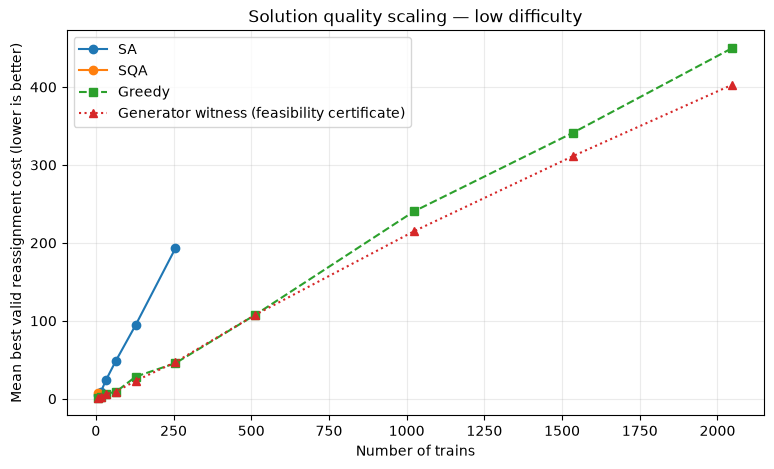

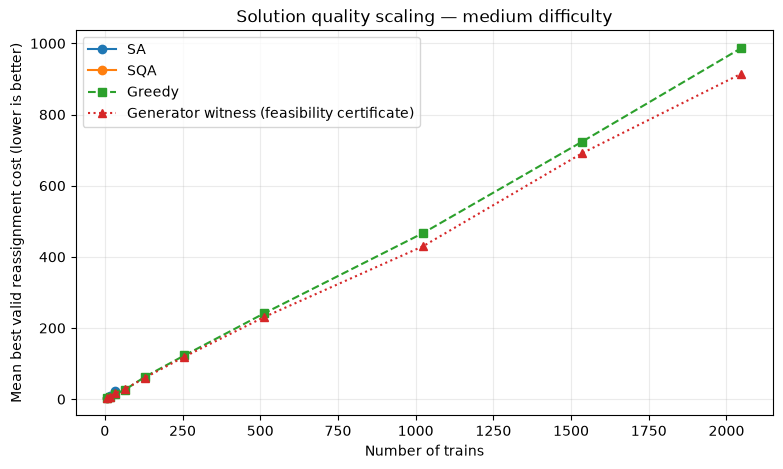

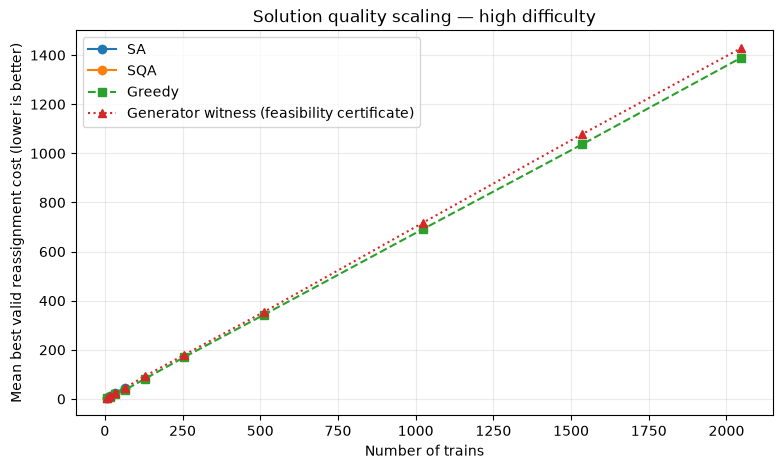

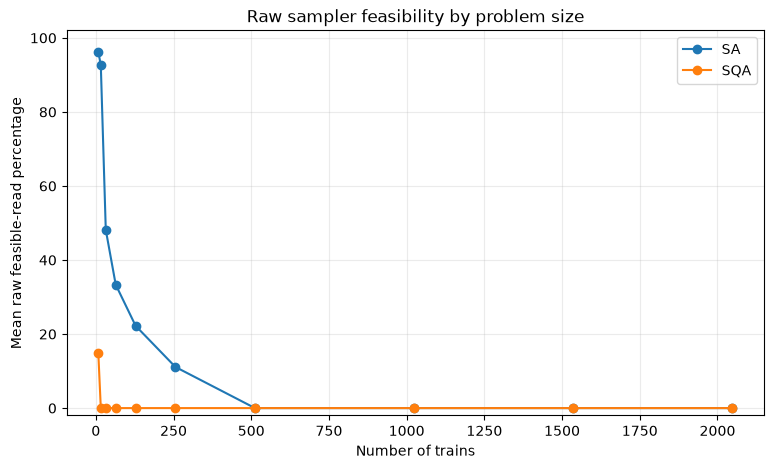

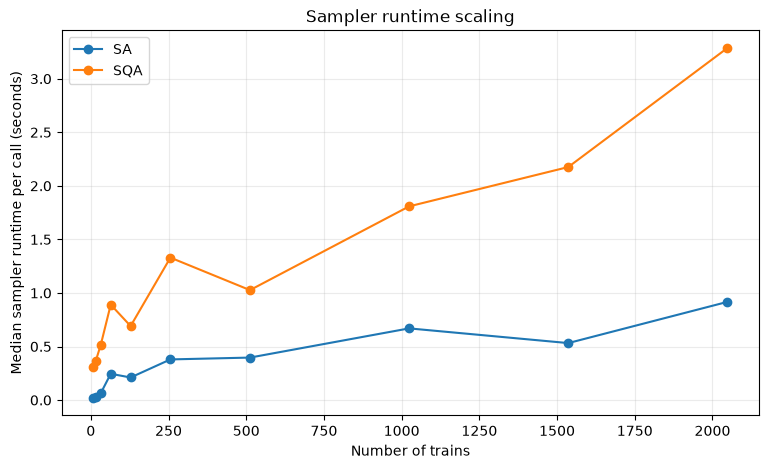

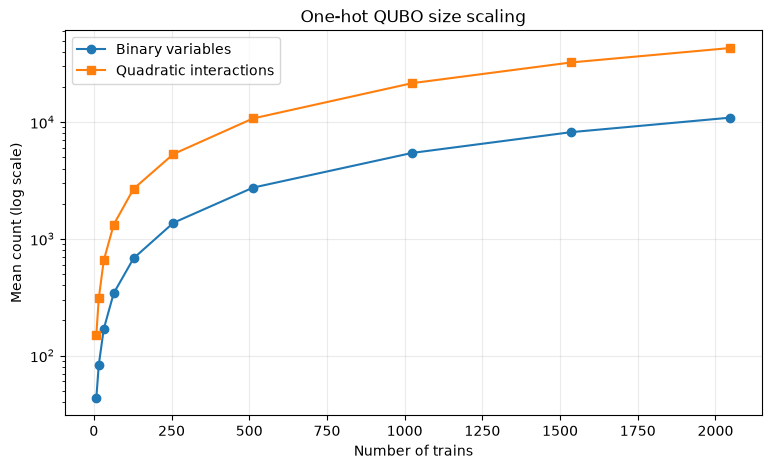

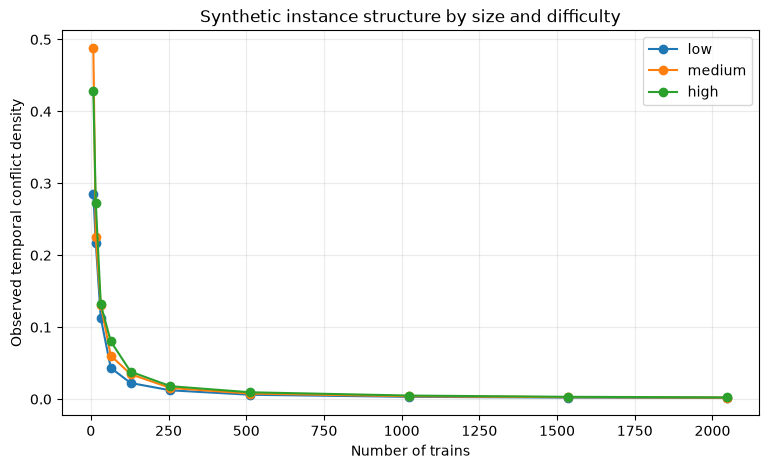

In [10]:
if not sampler_runs.empty:
    dataset_algorithm_summary = (sampler_runs.groupby(
        ["dataset_id","n_trains","difficulty","algorithm"],dropna=False)
        .agg(repeats=("repeat","nunique"),successful_runs=("run_status",lambda x:int((x=="OK").sum())),
             best_valid_cost=("best_valid_cost","min"),mean_best_valid_cost=("best_valid_cost","mean"),
             mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             median_sampler_runtime_s=("runtime_s","median"),
             median_end_to_end_s=("end_to_end_s","median"))
        .reset_index().merge(dataset_diagnostics[["dataset_id","greedy_cost","exact_status","exact_cost","conflict_density"]],
                             on="dataset_id",how="left"))
    dataset_algorithm_summary["gap_to_exact"] = np.where(
        dataset_algorithm_summary.exact_status=="OPTIMAL",
        dataset_algorithm_summary.best_valid_cost-dataset_algorithm_summary.exact_cost,np.nan)
    dataset_algorithm_summary["gap_to_greedy"] = dataset_algorithm_summary.best_valid_cost-dataset_algorithm_summary.greedy_cost

    scaling_summary = (dataset_algorithm_summary.groupby(["n_trains","difficulty","algorithm"],dropna=False)
        .agg(datasets=("dataset_id","nunique"),
             mean_best_valid_cost=("best_valid_cost","mean"),
             median_best_valid_cost=("best_valid_cost","median"),
             mean_feasibility_pct=("mean_raw_feasibility_pct","mean"),
             median_sampler_runtime_s=("median_sampler_runtime_s","median"),
             median_end_to_end_s=("median_end_to_end_s","median"),
             mean_gap_to_exact=("gap_to_exact","mean"),
             wins_over_greedy=("gap_to_greedy",lambda x:int((x<0).sum())),
             valid_dataset_count=("best_valid_cost",lambda x:int(x.notna().sum())))
        .reset_index())

    print("Scaling summary by size, difficulty and algorithm:")
    display(scaling_summary)
    print("Exact-search statuses:")
    display(dataset_diagnostics.groupby(["n_trains","exact_status"]).size().rename("datasets").reset_index())
    print("Observed conflict structure and platform utilisation (do not assume difficulty ordering):")
    display(dataset_diagnostics.groupby(["n_trains","difficulty"])[
        ["conflict_density","mean_conflict_degree","max_concurrent_trains",
         "mean_observed_witness_platform_utilization"]].mean().reset_index())

    # 1. Best feasible solution quality, separated by difficulty.
    for difficulty in DIFFICULTIES:
        fig,ax=plt.subplots(figsize=(9,5))
        sub=scaling_summary[scaling_summary.difficulty==difficulty]
        for alg in ["SA","SQA"]:
            d=sub[sub.algorithm==alg].sort_values("n_trains")
            ax.plot(d.n_trains,d.mean_best_valid_cost,marker="o",label=alg)
        gd=dataset_diagnostics[dataset_diagnostics.difficulty==difficulty].groupby("n_trains").greedy_cost.mean()
        ax.plot(gd.index,gd.values,marker="s",linestyle="--",label="Greedy")
        wd=dataset_diagnostics[dataset_diagnostics.difficulty==difficulty].groupby("n_trains").witness_cost.mean()
        ax.plot(wd.index,wd.values,marker="^",linestyle=":",label="Generator witness (feasibility certificate)")
        ax.set_xlabel("Number of trains"); ax.set_ylabel("Mean best valid reassignment cost (lower is better)")
        ax.set_title(f"Solution quality scaling — {difficulty} difficulty")
        ax.grid(alpha=.25); ax.legend(); plt.show()

    # 2. Raw feasibility.
    fig,ax=plt.subplots(figsize=(9,5))
    for alg in ["SA","SQA"]:
        d=scaling_summary[scaling_summary.algorithm==alg].groupby("n_trains").mean_feasibility_pct.mean().reset_index()
        ax.plot(d.n_trains,d.mean_feasibility_pct,marker="o",label=alg)
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Mean raw feasible-read percentage")
    ax.set_title("Raw sampler feasibility by problem size")
    ax.set_ylim(-2,102); ax.grid(alpha=.25); ax.legend(); plt.show()

    # 3. Runtime, measured separately from QUBO construction.
    fig,ax=plt.subplots(figsize=(9,5))
    for alg in ["SA","SQA"]:
        d=sampler_runs[(sampler_runs.algorithm==alg)&(sampler_runs.run_status=="OK")].groupby("n_trains").runtime_s.median().reset_index()
        ax.plot(d.n_trains,d.runtime_s,marker="o",label=alg)
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Median sampler runtime per call (seconds)")
    ax.set_title("Sampler runtime scaling")
    ax.grid(alpha=.25); ax.legend(); plt.show()

    # 4. Formulation size.
    fig,ax=plt.subplots(figsize=(9,5))
    d=qubo_model_metrics[qubo_model_metrics.build_status=="BUILT"].groupby("n_trains").agg(
        variables=("n_variables","mean"),interactions=("n_quadratic_interactions","mean")).reset_index()
    ax.plot(d.n_trains,d.variables,marker="o",label="Binary variables")
    ax.plot(d.n_trains,d.interactions,marker="s",label="Quadratic interactions")
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Mean count (log scale)")
    ax.set_yscale("log"); ax.set_title("One-hot QUBO size scaling")
    ax.grid(alpha=.25); ax.legend(); plt.show()

    # 5. Conflict density by scenario.
    fig,ax=plt.subplots(figsize=(9,5))
    for diff in DIFFICULTIES:
        d=dataset_diagnostics[dataset_diagnostics.difficulty==diff].groupby("n_trains").conflict_density.mean().reset_index()
        ax.plot(d.n_trains,d.conflict_density,marker="o",label=diff)
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Observed temporal conflict density")
    ax.set_title("Synthetic instance structure by size and difficulty")
    ax.grid(alpha=.25); ax.legend(); plt.show()
else:
    dataset_algorithm_summary=scaling_summary=pd.DataFrame()
    print("No sampler output to summarize.")

## 10. Export results and experiment metadata

In [11]:
OUTPUT_DIR = Path.cwd() / "railway_v9_outputs"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

def export_frame(frame,name):
    if frame is None or frame.empty:
        print("Not exported (empty):",name)
        return
    path=OUTPUT_DIR/name
    frame.to_csv(path,index=False)
    print("Saved:",path)

export_frame(dataset_diagnostics,"railway_v9_dataset_diagnostics.csv")
export_frame(generated_train_tables,"railway_v9_generated_train_tables.csv")
export_frame(conflict_edge_tables,"railway_v9_conflict_edges.csv")
export_frame(qubo_model_metrics,"railway_v9_qubo_model_metrics.csv")
export_frame(sampler_runs,"railway_v9_sampler_runs.csv")
export_frame(dataset_algorithm_summary,"railway_v9_dataset_algorithm_summary.csv")
export_frame(scaling_summary,"railway_v9_scaling_summary.csv")

metadata = {
    "notebook_version":"v9_generalised_one_hot_scaling_benchmark",
    "study_mode":STUDY_MODE,"python_version":sys.version.split()[0],
    "platform":platform.platform(),"cpu":platform.processor(),"ram_gb":RAM_GB,
    "openjij_version":OPENJIJ_VERSION,"n_platforms":N_PLATFORMS,
    "long_platform_count":LONG_PLATFORM_COUNT,"long_train_coach_threshold":LONG_TRAIN_COACH_THRESHOLD,
    "clearance_min_assumption":CLEARANCE_MIN,"train_counts":TRAIN_COUNTS,
    "seeds_by_size":SEEDS_BY_SIZE,"difficulty_levels":DIFFICULTIES,"difficulty_config":DIFFICULTY_CONFIG,
    "dataset_count":len(dataset_diagnostics) if not dataset_diagnostics.empty else 0,
    "encoding":"one_hot","algorithms":["SA","SQA"],"greedy_restarts":GREEDY_RESTARTS,
    "budget_by_size":BUDGET_BY_SIZE,"budget_tier_rule":"small <=64; medium 65-256; large >256",
    "exact_max_trains":EXACT_MAX_TRAINS,"exact_time_limit_s":EXACT_TIME_LIMIT_S,
    "max_qubo_variables":MAX_QUBO_VARIABLES,"max_qubo_interactions":MAX_QUBO_INTERACTIONS,
    "qubo_identity_all_built_passed":bool(qubo_model_metrics.loc[qubo_model_metrics.build_status=="BUILT","identity_passed"].all()) if not qubo_model_metrics.empty else None,
    "sampler_success_rows":int((sampler_runs.run_status=="OK").sum()) if not sampler_runs.empty else 0,
    "sampler_error_rows":int((sampler_runs.run_status=="ERROR").sum()) if not sampler_runs.empty else 0,
    "resource_skipped_datasets":int((~dataset_diagnostics.resource_gate_passed).sum()) if not dataset_diagnostics.empty else 0,
    "synthetic_data_notice":"All train-level schedules, delays, nominal platform assignments, coach counts and conflicts are synthetic; no station-specific dataset is used.",
    "quantum_notice":"OpenJij SQA is a classical simulation, not quantum hardware.",
    "raw_feasibility_notice":"No repair decoder is applied; only internally valid conflict-free raw sampler samples count as feasible.",
    "interpretation_notice":"Timeouts and resource skips are not infeasibility proofs or solver failures. Exact optimality gaps are reported only for proven OPTIMAL exact searches.",
    "scenario_notice":"Difficulty changes per-platform target utilisation and nominal/witness agreement probability. Observed conflict density, mean degree and maximum concurrency are exported for audit."
}
with open(OUTPUT_DIR/"railway_v9_experiment_metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata,f,indent=2)
print("V9 outputs saved to:",OUTPUT_DIR.resolve())

Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_outputs\railway_v9_outputs\railway_v9_dataset_diagnostics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_outputs\railway_v9_outputs\railway_v9_generated_train_tables.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_outputs\railway_v9_outputs\railway_v9_conflict_edges.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_outputs\railway_v9_outputs\railway_v9_qubo_model_metrics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_outputs\railway_v9_outputs\railway_v9_sampler_runs.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_outputs\railway_v9_outputs\railway_v9_dataset_algorithm_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_outputs\railway_v9_outputs\railway_v9_scaling_summary.csv
V9 outputs saved to: C:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v9_outputs\railway_v9_outputs


## 11. Mandatory review checklist before treating results as evidence

- [ ] Pilot QUBO identity checks and exhaustive tiny-instance check pass.
- [ ] All generated assignments respect eligibility and all conflict edges are generated from actual intervals plus the stated clearance.
- [ ] Greedy feasibility is reported as a heuristic result, not an infeasibility proof.
- [ ] Every sampler row includes status, runtime, reads, sweeps, and repeat number.
- [ ] Raw sampler feasibility is separated from solution quality; no repaired samples are counted.
- [ ] Exact `OPTIMAL` is the only status used to calculate an optimality gap.
- [ ] `TIMEOUT`, `NOT_RUN_SIZE_LIMIT`, and `SKIPPED_RESOURCE_LIMIT` remain distinct.
- [ ] Observed conflict density is checked for each size and difficulty; labels are not treated as ground-truth hardness.
- [ ] Pilot results are reviewed before running `FULL`.
- [ ] All CSVs and metadata are retained alongside the executed notebook.

**V9 stop/go rule:** proceed to the extended full benchmark only if the pilot is reproducible, there are no identity-check failures, resource use is understood, and the observed instance structure is sufficiently varied to support the intended comparison. If higher train counts do not produce harder instances, revise the scenario generator transparently before claiming scalability under increasing difficulty.